In [1]:
import os
import re
import html
import string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

## Ερώτημα 1



In [3]:
if os.path.exists('train.csv'):
    data_dir = '.'


df = pd.read_csv(os.path.join(data_dir, 'train.csv'))
print(df.shape)
df.head()

(7613, 5)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [4]:
train_df, test_df = train_test_split(df, test_size=0.1, stratify=df['target'], random_state=0)
print('train:', len(train_df), 'tweets')
print('test: ', len(test_df), 'tweets')

train: 6851 tweets
test:  762 tweets


                    train  test
0 - όχι καταστροφή   3907   435
1 - καταστροφή       2944   327


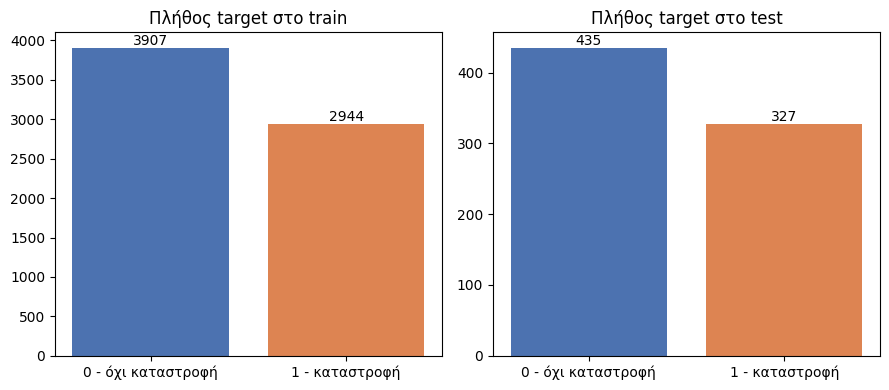

In [5]:
plot_df = pd.DataFrame({
    'train': train_df['target'].value_counts(),
    'test': test_df['target'].value_counts(),
}).sort_index()
plot_df.index = ['0 - όχι καταστροφή', '1 - καταστροφή']
print(plot_df)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col in zip(axes, ['train', 'test']):
    bars = ax.bar(plot_df.index, plot_df[col], color=['#4c72b0', '#dd8452'])
    ax.bar_label(bars)
    ax.set_title(f'Πλήθος target στο {col}')
plt.tight_layout()
plt.show()

Υπάρχει μια μικρή ανισορροπία στις κλάσεις (~57% για το 0 και ~43% για το 1), αλλά επειδή η απόκλιση είναι μικρή, δεν απαιτείται resampling. Απλώς, λόγω του stratify, οι αναλογίες παραμένουν ακριβώς οι ίδιες τόσο στο train όσο και στο test set.

## Ερώτημα 2

In [6]:
print(train_df.isna().sum())

id             0
keyword       54
location    2264
text           0
target         0
dtype: int64


Ελλιπείς τιμές έχουν μόνο το keyword και το location. Το location το αφαιρώ ούτως ή άλλως, οπότε το fillna επηρεάζει μόνο το keyword.

In [7]:
def prepare(d):
    d = d.drop(columns=['id', 'location'])
    d = d.fillna('null')
    d['inputs'] = d['keyword'] + ' ' + d['text']
    return d

train_df = prepare(train_df)
test_df = prepare(test_df)
train_df[['inputs', 'target']].head()

,inputs,target
6669,threat Meek Mill responds to DrakeÛªs OVO Fes...,1
3940,flood survived the plague\nfloated the flood\n...,0
7217,weapons #Kick Hendrixonfire @'=BLACKCATS= | B...,0
2234,deluge Vince McMahon once again a billionaire:...,0
4233,hazardous Is it possible to sneak into a hospi...,0


## Ερώτημα 3

Οι συναρτήσεις είναι από το [Deffro/text-preprocessing-techniques](https://github.com/Deffro/text-preprocessing-techniques)

In [8]:
def removeUnicode(text):
    # Removes unicode strings like "," and "x96"
    text = re.sub(r'(\\u[0-9A-Fa-f]+)', r'', text)
    text = re.sub(r'[^\x00-\x7f]', r'', text)
    return text

def replaceURL(text):
    # Replaces url address with "url"
    text = re.sub(r'((www\.[^\s]+)|(https?://[^\s]+))', 'url', text)
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text

def replaceAtUser(text):
    # Replaces "@user" with "atUser"
    text = re.sub(r'@[^\s]+', 'atUser', text)
    return text

def removeHashtagInFrontOfWord(text):
    # Removes hashtag in front of a word
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text

| Τεχνική | Τι κάνει / γιατί |
|---|---|
| removeUnicode | Βγάζει τα emoji και τα χαλασμένα σύμβολα (π.χ. `Ûª`), που δεν έχουν νόημα για το μοντέλο. |
| replaceURL | Κάνει κάθε link τη λέξη `url`, γιατί μας νοιάζει μόνο ότι υπάρχει link και όχι ποιο είναι. |
| replaceAtUser | Κάνει κάθε `@όνομα` σε `atuser`, αφού το ποιος αναφέρεται δεν δείχνει αν έγινε καταστροφή. |
| removeHashtagInFrontOfWord | Βγάζει το `#`, ώστε το `#earthquake` να μετράει ίδιο με το `earthquake`. |
| lowercase | Τα κάνει όλα πεζά, για να μη μετράνε τα `FLOOD`, `Flood` και `flood` σαν τρεις λέξεις. |
| αφαίρεση στίξης | Βγάζει τελείες, κόμματα κλπ, ώστε να μείνουν μόνο λέξεις. |
| stopwords | Βγάζει πολύ συχνές λέξεις (the, is, and) και λέξεις με ένα γράμμα, γιατί υπάρχουν σχεδόν σε όλα τα tweets και δεν βοηθάνε. |
| lemmatization | Κάνει τα ουσιαστικά ενικό (`floods` → `flood`), ώστε να μετράνε ως μία λέξη. Τα ρήματα (π.χ. `burning`) μένουν ίδια. |

In [9]:
stoplist = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_tweet(text):
    text = removeUnicode(text)
    text = replaceURL(text)
    text = replaceAtUser(text)
    text = removeHashtagInFrontOfWord(text)
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    words = [lemmatizer.lemmatize(w) for w in text.split() if w not in stoplist and len(w) > 1]
    return ' '.join(words)

# παράδειγμα σε ένα tweet
#example = train_df['inputs'].iloc[28]
#print('πριν:', example)
#print('μετά:', clean_tweet(example))

πριν: collide #Vancouver to host 100s of electronic art events including @MUTEK_Montreal. http://t.co/vjBhxN9x1O #ISEA2015
μετά: collide vancouver host 100 electronic art event including atuser url isea2015


In [10]:
train_df['inputs'] = train_df['inputs'].apply(clean_tweet)
test_df['inputs'] = test_df['inputs'].apply(clean_tweet)
train_df[['inputs', 'target']].head(8)

,inputs,target
6669,threat meek mill responds drake ovo fest set w...,1
3940,flood survived plague floated flood peeked hea...,0
7217,weapon kick hendrixonfire atuser big noob conq...,0
2234,deluge vince mcmahon billionaire remember read...,0
4233,hazardous possible sneak hospital stab hazardo...,0
6050,sinkhole large sinkhole swallow entire pond lo...,1
6518,survive going three year separated sometimes l...,0
1290,burned atuser atuser keithyy gettin burned out...,0


## Ερώτημα 4

In [11]:
X_train = train_df['inputs'].to_numpy()
y_train = train_df['target'].to_numpy()
X_test = test_df['inputs'].to_numpy()
y_test = test_df['target'].to_numpy()

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(6851,) (6851,)
(762,) (762,)


## Ερώτημα 5



In [12]:
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print('λέξεις στο λεξιλόγιο:', len(vectorizer.vocabulary_))
print(X_train_tfidf.shape, X_test_tfidf.shape)

λέξεις στο λεξιλόγιο: 13388
(6851, 13388) (762, 13388)


In [13]:
# tf-idf των λέξεων του πρώτου tweet
words = vectorizer.get_feature_names_out()
first = X_train_tfidf[0]
print(X_train[0])
pd.Series(first.data, index=words[first.indices]).sort_values(ascending=False).round(3)

threat meek mill responds drake ovo fest set wedgie threat url


,0
threat,0.531
wedgie,0.347
fest,0.331
ovo,0.331
responds,0.305
mill,0.299
meek,0.268
drake,0.265
set,0.224
url,0.063


## Ερώτημα 6

Ο GaussianNB δεν δέχεται sparse πίνακα, οπότε τον μετατρέπω σε κανονικό με toarray().

In [15]:
gnb = GaussianNB()
gnb.fit(X_train_tfidf.toarray(), y_train)

y_pred = gnb.predict(X_test_tfidf.toarray())

print('train accuracy:', round(accuracy_score(y_train, gnb.predict(X_train_tfidf.toarray())), 3))
print('test accuracy: ', round(accuracy_score(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=['όχι καταστροφή', 'καταστροφή']))

train accuracy: 0.875
test accuracy:  0.635

                precision    recall  f1-score   support

όχι καταστροφή       0.79      0.50      0.61       435
    καταστροφή       0.55      0.82      0.66       327

      accuracy                           0.64       762
     macro avg       0.67      0.66      0.63       762
  weighted avg       0.68      0.64      0.63       762



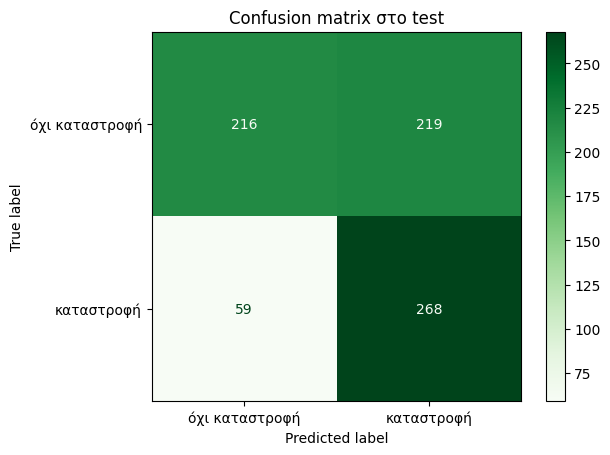

σωστά αναγνωρισμένες καταστροφές: 268 από 327
λάθος συναγερμοί: 219 από 435 tweets χωρίς καταστροφή


In [16]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['όχι καταστροφή', 'καταστροφή'], cmap='Greens')
plt.title('Confusion matrix στο test')
plt.show()

from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'σωστά αναγνωρισμένες καταστροφές: {tp} από {tp + fn}')
print(f'λάθος συναγερμοί: {fp} από {tn + fp} tweets χωρίς καταστροφή')


## Συμπεράσματα

Στο test set το μοντέλο έχει accuracy 0.635. Από τα 327 tweets με καταστροφή βρήκε τα 268 (recall 0.82), όμως από τα 435 tweets χωρίς καταστροφή
τα 219 τα χαρακτήρισε λάθος ως καταστροφή. Δηλαδή χάνει λίγες πραγματικές καταστροφές, αλλά δίνει πάρα πολλούς ψεύτικους συναγερμούς.
Για το 112 αυτό δεν είναι αποδεκτό, γιατί αν ο κόσμος λαμβάνει συχνά μηνύματα χωρίς λόγο, κάποια στιγμή θα σταματήσει να τα προσέχει.

Στο train το accuracy είναι 0.875, πολύ πιο ψηλά από το test, άρα το μοντέλο κάνει overfitting.
